In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import scipy.stats as stats
import sympy as sym
import matplotlib.pyplot as plt
import cvxpy as cv

Part A

In [11]:
golf = pd.read_csv("time_series_US_20031231-1800_20261013-2329.csv")
golf = golf[golf['Time'] <= '2025-09-01'].reset_index(drop=True)
N = len(golf)
y = golf['golf'].to_numpy(dtype=float)
t = np.arange(1, N+1)

X = np.zeros((N, N))
X[:, 0] = 1
for i in range(1, N):
    X[:, i] = np.maximum(t - i, 0)

In [12]:
K = 5
idx = np.arange(N)

D = np.ones(N)
D[:2] = 0                  
D = np.diag(D)

lmbda = np.logspace(-3, 6, 91)

cv_error = []
for lam in lmbda:
    fold_error = []
    for k in range(K):
        test  = (idx % K == k)
        train = ~test
        X_train, y_train = X[train], y[train]
        X_test,  y_test  = X[test],  y[test]

        A = X_train.T @ X_train + lam * D
        b = X_train.T @ y_train
        beta_hat = np.linalg.solve(A, b)

        pred = X_test @ beta_hat
        fold_error.append(np.mean((y_test - pred)**2))
    cv_error.append(np.mean(fold_error))

best_i = np.argmin(cv_error)
best_lam = lmbda[best_i]
print(f"best lambda = {best_lam:.3g}  (grid index {best_i} of {len(lmbda)-1})")


best lambda = 0.398  (grid index 26 of 90)


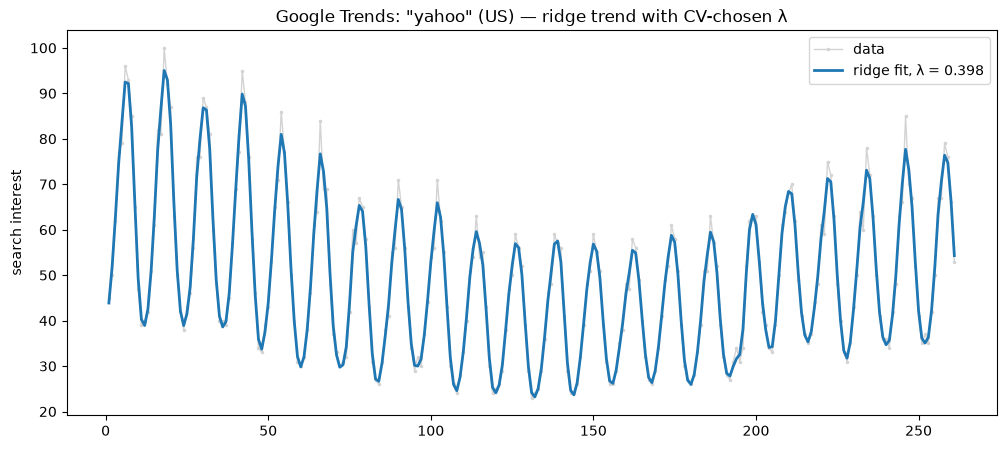

In [13]:
A = X.T @ X + best_lam * D
beta_best = np.linalg.solve(A, X.T @ y)
mu_best = X @ beta_best

plt.figure(figsize=(12, 5))
plt.plot(t, y, color='lightgray', lw=1, marker='.', ms=3, label='data')
plt.plot(t, mu_best, color='C0', lw=2, label=f'ridge fit, λ = {best_lam:.3g}')
plt.ylabel('search interest'); plt.title('Google Trends: "yahoo" (US) — ridge trend with CV-chosen λ')
plt.legend()
plt.show()

The model seems to find the overal trend of the data quite well however it fails to fully capture the peaks. Furthermore we see that it almost always fails to grasp the true peak of each period.

Part B

i

In [14]:
n = len(y)
XtX = X.T @ X
Xty = X.T @ y
yty = y @ y

def log_post(tau, sigma):
    M = XtX / sigma**2 + D / tau**2
    _, logdetM = np.linalg.slogdet(M)
    quad = Xty @ np.linalg.solve(M, Xty) / sigma**4
    return (-(n - 2) * np.log(tau) - n * np.log(sigma)
            - 0.5 * logdetM - 0.5 * (yty / sigma**2 - quad))

# grid centered on the part (a) estimates
sig0 = np.std(y - mu_best)
tau0 = sig0 / np.sqrt(best_lam)
taus   = tau0 * np.logspace(-2, 2, 60)
sigmas = sig0 * np.logspace(-1, 1, 60)

LP = np.array([[log_post(ta, si) for si in sigmas] for ta in taus])

i, j = np.unravel_index(np.argmax(LP), LP.shape)
tau_hat, sigma_hat = taus[i], sigmas[j]
print(f"tau_hat = {tau_hat:.4g}, sigma_hat = {sigma_hat:.4g}")
print(f"sigma^2/tau^2 = {sigma_hat**2 / tau_hat**2:.4g}   vs   CV lambda = {best_lam:.4g}")



tau_hat = 6.66, sigma_hat = 2.53
sigma^2/tau^2 = 0.1443   vs   CV lambda = 0.3981


ii

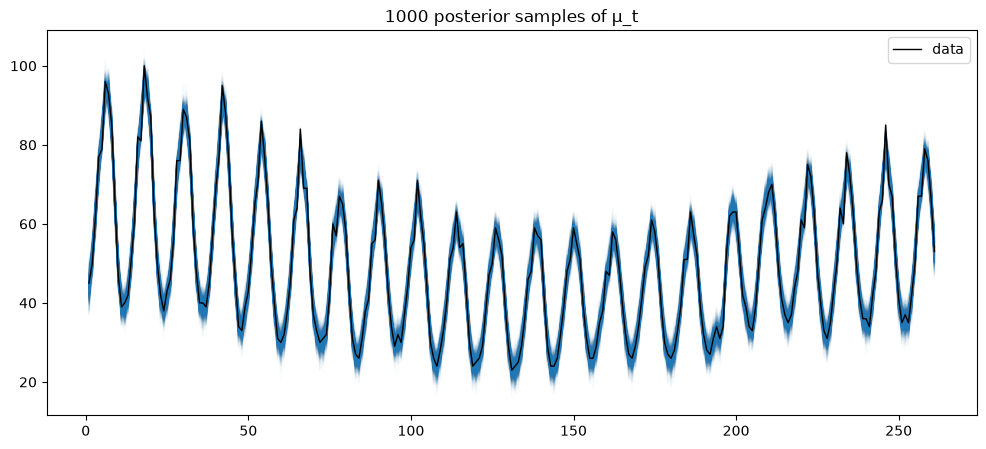

In [15]:
from scipy.linalg import cho_factor, cho_solve, solve_triangular

rng = np.random.default_rng(0)
Nsamp = 1000

# 1. sample (tau, sigma) from the grid posterior
P = np.exp(LP - LP.max())
P /= P.sum()
flat = rng.choice(P.size, size=Nsamp, p=P.ravel())
ti, si = np.unravel_index(flat, P.shape)

# 2. for each (tau, sigma), sample beta ~ N(M^-1 X'y / sigma^2, M^-1)
mu_samples = np.empty((Nsamp, n))
for s in range(Nsamp):
    tau, sigma = taus[ti[s]], sigmas[si[s]]
    M = XtX / sigma**2 + D / tau**2
    c, low = cho_factor(M, lower=True)               # M = L L^T
    mean = cho_solve((c, low), Xty / sigma**2)
    z = rng.standard_normal(n)
    beta = mean + solve_triangular(c, z, lower=True, trans='T')  # cov = M^-1
    mu_samples[s] = X @ beta

# 3. plot
plt.figure(figsize=(12, 5))
plt.plot(t, y, color='black', lw=1, label='data', zorder=3)
for s in range(Nsamp):
    plt.plot(t, mu_samples[s], color='C0', alpha=0.02, lw=1)
plt.title('1000 posterior samples of μ_t')
plt.legend()
plt.show()

The level of uncertainly is roughly as expected have the peaks and troughs have a visibily higher level of uncertainty. Similarly we see that the band of uncertainty is a lot tighter in that middle space which makes sense from our model observed especially when comparing back to the ridge model in a where it fit the general trend quite well but not the peaks and troughs.

iii

roughness  ridge (CV): 5005
roughness  Bayes mean: 6993


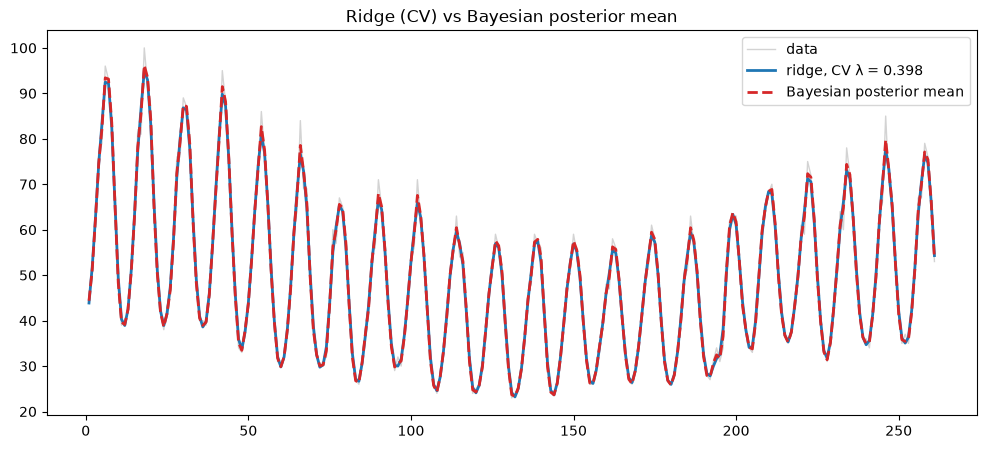

In [16]:
mu_bayes = mu_samples.mean(axis=0)

# smoothness: sum of squared second differences (smaller = smoother)
rough = lambda m: np.sum(np.diff(m, 2)**2)
print(f"roughness  ridge (CV): {rough(mu_best):.4g}")
print(f"roughness  Bayes mean: {rough(mu_bayes):.4g}")

plt.figure(figsize=(12, 5))
plt.plot(t, y, color='lightgray', lw=1, label='data')
plt.plot(t, mu_best, color='C0', lw=2, label=f'ridge, CV λ = {best_lam:.3g}')
plt.plot(t, mu_bayes, color='C3', lw=2, ls='--', label='Bayesian posterior mean')
plt.title('Ridge (CV) vs Bayesian posterior mean')
plt.legend()
plt.show()

Here it looks like the bayesian posterier means fits the trend far better as it is able to capture the peaks and dips slightly better than that of the ridge model. However it still faces issues fully capture the peaks.